# 02 — Validate one SWOT pass on **GS_AOI5**, then label the full catalog

Same pipeline as `01_validate_pass.ipynb` (de Marez et al. 2026: pad 69→128, 128×128 /
64-overlap tiles, biharmonic inpaint, PET shape_error 85, R_max + gap test on the speed
contour, min R 5 km, min amp 0.01 m) — but the study area is now the **GS_AOI5 polygon**
(concave; clips the SE open ocean, keeps the Gulf Stream + inland).

**Two stages:** (1) run + vet **one pass** with the polygon clip made visible (in-AOI vs
out-AOI detections, polygon outline drawn), then (2) **label the whole catalog** (all 50
cycles already detected into `out/aoi5/`) with 4 classes **frontal / coastal / open ocean /
reject**. Polarity stays auto (PET, from SLA sign).

Crop runs on the polygon's **envelope** (rectangle); detections are filtered to the true
polygon by their center (`aoi.contains`). Filter-only — no pixel masking — so the inpaint
never fabricates field along the cut. Logic lives in `src/swot_eddy/{aoi,preprocess,detect}.py`.

In [1]:
# Auto-reload edited swot_eddy modules so source changes take effect without a kernel restart.
%load_ext autoreload
%autoreload 2

In [2]:
import re, datetime as dt
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from swot_eddy.config import load_config
from swot_eddy.aoi import load_aoi
from swot_eddy import preprocess as pp
from swot_eddy.detect import detect_pass

cfg = load_config()
aoi = load_aoi(cfg)                         # GS_AOI5 polygon (point-in-polygon filter)
# cfg['region'] is now the polygon ENVELOPE, auto-injected by load_config() (crop band).
print("AOI5 envelope (crop band):", {k: round(v, 3) for k, v in cfg['region'].items()})

path = Path(cfg["data_root"]) / cfg["example_file"]
m = re.search(r"_(\d{8})T(\d{6})_", path.name)
date = dt.datetime.strptime(m.group(1) + m.group(2), "%Y%m%d%H%M%S") if m else dt.datetime(2023, 8, 14)
print(path.name, "| pass date:", date)

AOI5 envelope (crop band): {'lon_min': -85.48, 'lat_min': 23.321, 'lon_max': -68.406, 'lat_max': 40.793}
SWOT_L3_LR_SSH_Expert_043_410_20251228T034857_20251228T044023_v3.0.nc | pass date: 2025-12-28 03:48:57


## Preprocess (crop to AOI5 envelope → channels → pad → tile → inpaint)

In [3]:
tiles, summary, clon, clat = pp.preprocess_pass(str(path), cfg)
print("summary:", summary)
print("n_tiles:", len(tiles), "| tile0 shape:", tiles[0].data.shape,
      "| any NaN in tile0:", bool(np.isnan(tiles[0].data).any()))

summary: {'n_tiles': 15, 'n_lines_cropped': 1002, 'mdt_coverage': 0.45655066678237727, 'quality_max': None, 'line_slice': [2629, 3631], 'channels': ['ssha', 'adt']}
n_tiles: 15 | tile0 shape: (2, 128, 128) | any NaN in tile0: False


## Detect, then split on the AOI5 polygon

`detect_pass` already drops nadir/gap blobs. We then split the survivors by
`aoi.contains(center)`: **in-AOI** = kept for labeling, **out-AOI** = open-ocean detections
the polygon clips away. The out-AOI count is exactly what the new bound box removes vs the
old AOI3 rectangle.

In [4]:
dets, dsum = detect_pass(tiles, cfg, clon, clat, date)
in_aoi  = [d for d in dets if aoi.contains(d.center_lon, d.center_lat)]
out_aoi = [d for d in dets if not aoi.contains(d.center_lon, d.center_lat)]
print("detect summary:", dsum)
print(f"survivors: {len(dets)}  |  in-AOI (keep): {len(in_aoi)}  |  out-AOI (clipped): {len(out_aoi)}")
print("in-AOI polarity:",
      f"A{sum(d.polarity=='anticyclonic' for d in in_aoi)} / C{sum(d.polarity=='cyclonic' for d in in_aoi)}")

/mnt/c/Users/jspier/SWOT-eddy-ml/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:4824: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


detect summary: {'n_total': 55, 'n_nadir_reject': 5, 'n_gap_reject': 24, 'n_raw': 26, 'n_dedup': 16, 'n_kept': 16, 'n_rejected': 16, 'n_anticyclonic': 6, 'n_cyclonic': 10, 'n_nadir_center': 3, 'channel': 'ssha'}
survivors: 16  |  in-AOI (keep): 10  |  out-AOI (clipped): 6
in-AOI polarity: A4 / C6


## Reassemble full-pass fields (what PET saw)

In [5]:
def stitch(tiles, n_lines):
    C, _, P = tiles[0].data.shape
    full = np.full((C, n_lines, P), np.nan)
    for t in tiles:
        h = t.data.shape[1]
        e = min(t.line_start + h, n_lines)
        full[:, t.line_start:e, :] = t.data[:, :e - t.line_start, :]
    return full

n_lines = summary["n_lines_cropped"]
full = stitch(tiles, n_lines)              # (2, n_lines, 128): 0=ssha, 1=adt
pad_left = tiles[0].pad_left
print("full field shape:", full.shape)

full field shape: (2, 1002, 128)


## Overlay SSHA & ADT — in-AOI vs clipped detections

Red = anticyclonic, blue = cyclonic for **in-AOI** detections (solid; dashed = `gap_reject`).
**Gray** = **out-AOI**, the open-ocean detections the GS_AOI5 polygon removes. Dotted
verticals = real-data column band (`pad_left … +69`).

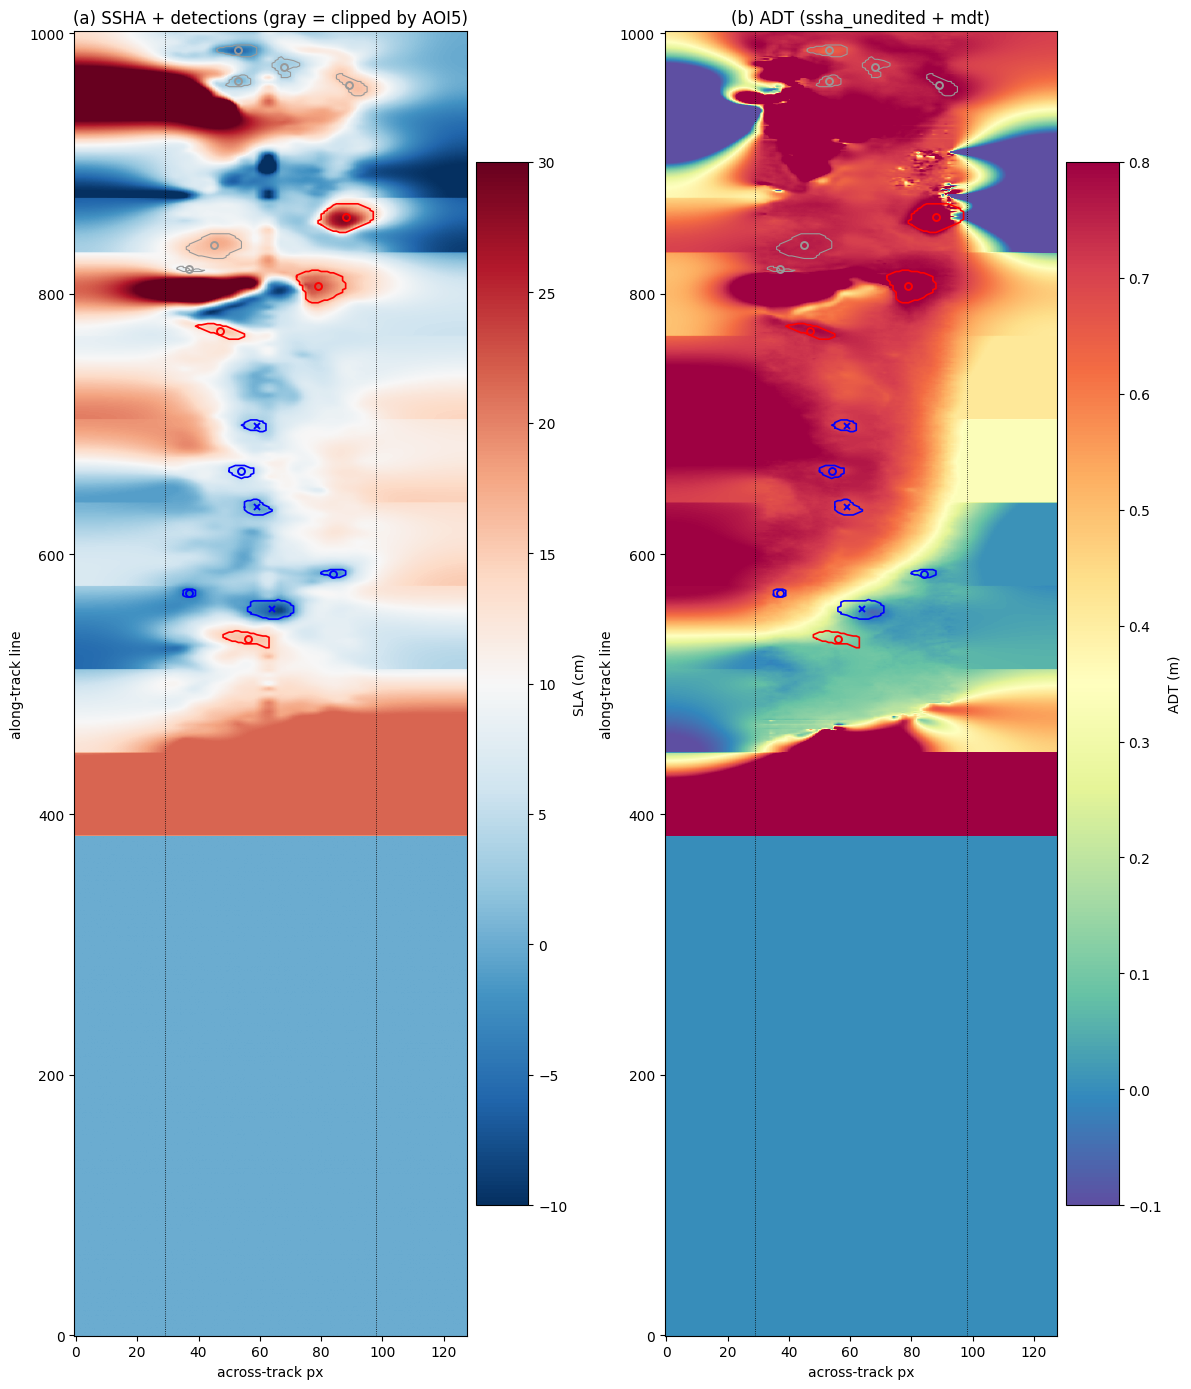

In [6]:
def overlay(ax, field2d, title, cmap, vmin, vmax, scale=1.0, label=""):
    im = ax.imshow(field2d * scale, cmap=cmap, vmin=vmin, vmax=vmax, origin="lower", aspect="auto")
    ax.axvline(pad_left, color="k", lw=0.6, ls=":"); ax.axvline(pad_left + 69, color="k", lw=0.6, ls=":")
    for d in dets:
        inside = aoi.contains(d.center_lon, d.center_lat)
        c = ("red" if d.polarity == "anticyclonic" else "blue") if inside else "0.6"
        ls = "--" if d.gap_reject else "-"
        if d.contour_pix:
            cl = np.array(d.contour_pix)
            ax.plot(cl[:, 1], cl[:, 0], color=c, lw=1.2 if inside else 0.8, ls=ls)
        mk = "x" if d.center_in_nadir else ("s" if d.gap_reject else "o")
        ax.plot(d.center_col, d.center_line, mk, color=c, ms=5, mfc="none", mew=1.4)
    ax.set_title(title); ax.set_xlabel("across-track px"); ax.set_ylabel("along-track line")
    fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02).set_label(label)

fig, ax = plt.subplots(1, 2, figsize=(12, 14))
overlay(ax[0], full[0], "(a) SSHA + detections (gray = clipped by AOI5)", "RdBu_r", -10, 30, scale=100, label="SLA (cm)")
overlay(ax[1], full[1], "(b) ADT (ssha_unedited + mdt)", "Spectral_r", -0.1, 0.8, label="ADT (m)")
plt.tight_layout(); plt.show()

## Geographic view with the **AOI5 polygon outline**

Native SWOT swath in true lon/lat (`pcolormesh`, no interpolation) with the GS_AOI5 polygon
boundary drawn in **green**. In-AOI kept eddies (red/blue, speed contour + center) sit inside
the polygon; the clipped (gray) ones fall outside — this is the visual proof the SE open
ocean is excluded. The crop is the polygon envelope, so part of the swath can extend past the
green edge; only centers inside the green line are kept.

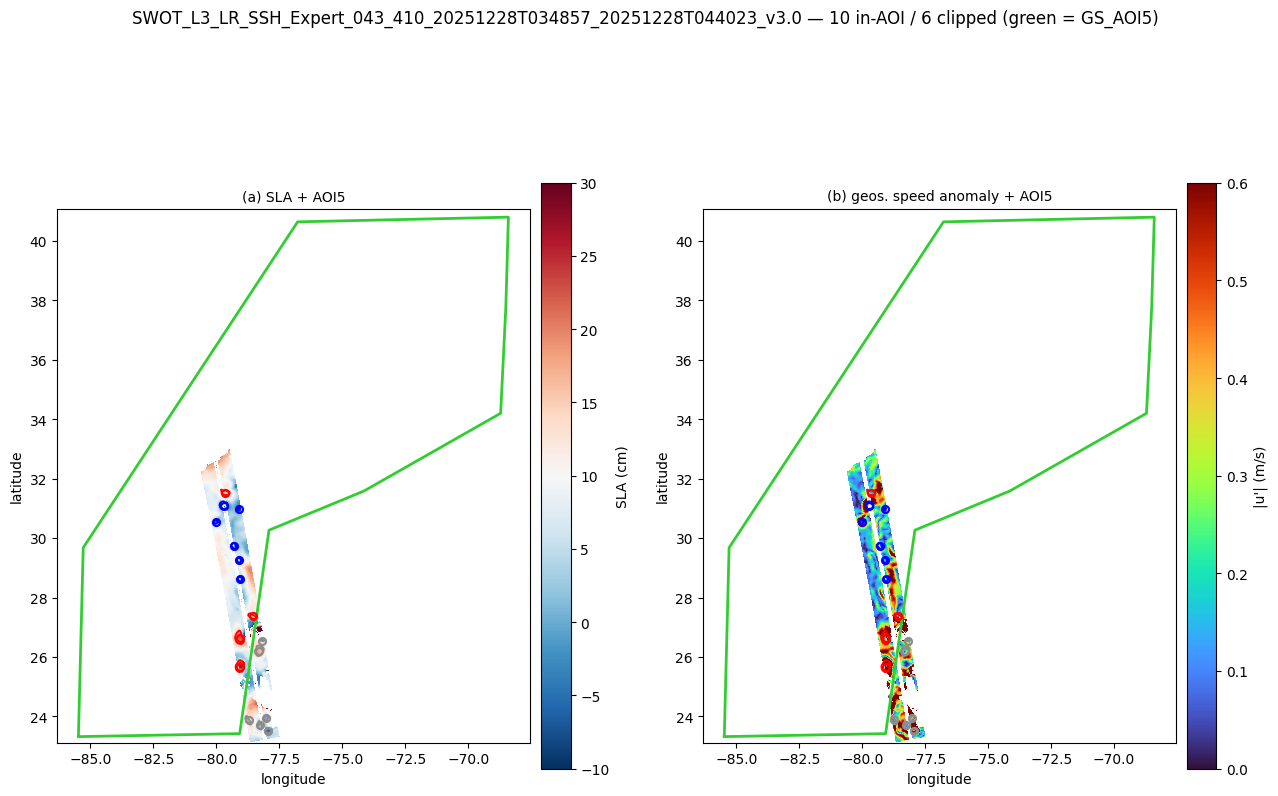

In [7]:
import xarray as xr
var_map = cfg["product"]["variables"][cfg["product"]["product_version"]]
to180 = lambda lo: ((lo + 180) % 360) - 180

with xr.open_dataset(str(path)) as ds_raw:
    dsg, _ = pp.crop_to_region(ds_raw, cfg["region"])      # envelope crop
glon = to180(dsg.longitude.values); glat = dsg.latitude.values
gsla = dsg[var_map["ssha"]].values * 100.0
gu, gv = dsg[var_map["ugosa"]].values, dsg[var_map["vgosa"]].values
midlat = float(np.nanmean(glat))

def aoi_rings(geom):
    """Exterior (x, y) of each polygon in the AOI (handles Polygon / MultiPolygon)."""
    geoms = geom.geoms if geom.geom_type == "MultiPolygon" else [geom]
    return [g.exterior.xy for g in geoms]

fig, ax = plt.subplots(1, 2, figsize=(13, 9))
for a, fld, cmap, vmin, vmax, lbl, ttl in (
        (ax[0], gsla, "RdBu_r", -10, 30, "SLA (cm)", "(a) SLA + AOI5"),
        (ax[1], np.hypot(gu, gv), "turbo", 0, 0.6, "|u'| (m/s)", "(b) geos. speed anomaly + AOI5")):
    pm = a.pcolormesh(glon, glat, fld, cmap=cmap, vmin=vmin, vmax=vmax, shading="nearest")
    for xs, ys in aoi_rings(aoi.geom):                    # AOI5 polygon boundary
        a.plot(xs, ys, color="limegreen", lw=2.0, zorder=5)
    for d in dets:
        if d.center_lon is None:
            continue
        inside = aoi.contains(d.center_lon, d.center_lat)
        c = ("red" if d.polarity == "anticyclonic" else "blue") if inside else "0.55"
        cl = [p for p in d.contour_lonlat if p is not None]
        if cl:
            arr = np.array(cl); a.plot(to180(arr[:, 0]), arr[:, 1], color=c, lw=1.3, zorder=6)
        a.plot(to180(d.center_lon), d.center_lat, "o", color=c, ms=5, mfc="none", mew=1.6, zorder=7)
    a.set_aspect(1 / np.cos(np.deg2rad(midlat)))
    a.set_xlabel("longitude"); a.set_ylabel("latitude"); a.set_title(ttl, fontsize=10)
    fig.colorbar(pm, ax=a, shrink=0.7, pad=0.02).set_label(lbl)
fig.suptitle(f"{path.stem} — {len(in_aoi)} in-AOI / {len(out_aoi)} clipped (green = GS_AOI5)", y=1.0)
plt.tight_layout(); plt.show()

## In-AOI detection table (manual-review surface)
`radius_km` = R_max (speed radius); `gap_rej` = paper reject flag. Only the in-AOI keepers.

In [8]:
import pandas as pd
df = pd.DataFrame([{
    "polarity": d.polarity, "line": d.center_line, "col": d.center_col,
    "lon": None if d.center_lon is None else round(to180(d.center_lon), 3),
    "lat": None if d.center_lat is None else round(d.center_lat, 3),
    "radius_km": round(d.radius_km, 1), "amp_m": round(d.amplitude_m, 3),
    "gap_frac": round(d.gap_frac, 2), "gap_rej": d.gap_reject,
    "nadir": d.center_in_nadir, "tile": d.source_tile,
} for d in in_aoi]).sort_values("amp_m", ascending=False)
display(df)

,polarity,line,col,lon,lat,radius_km,amp_m,gap_frac,gap_rej,nadir,tile
3,anticyclonic,859,88,-79.059,25.677,19.3,0.246,0.30,False,False,12
6,cyclonic,558,64,-79.718,31.094,14.6,0.090,0.56,False,True,8
2,anticyclonic,806,79,-79.073,26.647,19.5,0.073,0.07,False,False,12
4,cyclonic,636,59,-79.309,29.729,9.9,0.043,0.52,False,True,9
7,cyclonic,585,84,-80.020,30.546,6.7,0.043,0.00,False,False,8
0,anticyclonic,771,47,-78.565,27.372,12.6,0.038,0.00,False,False,11
8,cyclonic,664,54,-79.100,29.249,8.8,0.023,0.00,False,False,9
5,cyclonic,698,59,-79.073,28.629,8.2,0.020,0.52,False,True,10
9,cyclonic,570,37,-79.115,30.973,5.6,0.016,0.00,False,False,8
1,anticyclonic,535,56,-79.646,31.529,13.3,0.014,0.29,False,False,7


## Manual review of THIS pass (one eddy at a time)

Reuses `EddyReviewer` (8 panels: SLA / ADT / vel anomaly / vel full / wide context, then
full-swath SSHA / ADT / speed-anomaly with coastline). Runs over **in-AOI** eddies only, with
the same 4 classes as the full catalog labeler.

Buttons = **Frontal / Coastal / Open ocean / Reject** + Skip + Back / Next. **Hotkeys**:
`1` frontal, `2` coastal, `3` open ocean, `4` reject, `s` skip, left / right arrow = nav.
Polarity is not hand-labeled (PET sets it from SLA sign; shown red = anticyclonic /
blue = cyclonic). Writes a resumable per-pass CSV. This is the per-pass spot-check; the next
section labels the WHOLE catalog.

In [9]:
from swot_eddy.review import EddyReviewer

with xr.open_dataset(str(path)) as _ds:
    _dc, _ = pp.crop_to_region(_ds, cfg["region"])
    _gu, _gv = pp.geostrophic_anomaly_uv(_dc, var_map)
    _uf, _vf = _dc[var_map["ugos"]].values, _dc[var_map["vgos"]].values
    edge_cols = pp.swath_edge_cols(_dc)
    geo = (to180(_dc.longitude.values), _dc.latitude.values,
           _dc[var_map["ssha"]].values * 100.0,
           (_dc[var_map["ssha_adt_base"]] + _dc[var_map["mdt"]]).values,
           _gu, _gv)

cycle = path.parent.name
labels_path = Path(cfg["out_root"]) / "aoi5" / "labels" / "decisions.csv"
# Same 4 classes as the full catalog labeler: buttons Frontal/Coastal/Open ocean/Reject + Skip,
# hotkeys 1/2/3/4 = labels, s = skip, left/right arrow = nav.
EddyReviewer(in_aoi, full, pad_left, uv=(_gu, _gv), uv_full=(_uf, _vf), edge_cols=edge_cols,
             geo=geo, cycle=cycle, pass_name=path.stem, labels_path=labels_path,
             labels=("frontal", "coastal", "open ocean", "reject")).show()

<IPython.core.display.Javascript object>

## Label the WHOLE catalog — every eddy, every pass (4 classes)

All 50 cycles are already detected into `out/aoi5/catalog/` (via `scripts/run_all.py`).
`CatalogLabeler` walks **every detection across all passes** in two phases — (1) KEPT (good)
eddies, then (2) auto-REJECTED (nadir/gap) negatives — reading the AOI5 manifest and filtering
each pass's detections to the polygon.

Buttons = **Frontal / Coastal / Open ocean / Reject** + Skip + Back / Next. **Hotkeys**:
`1` frontal, `2` coastal, `3` open ocean, `4` reject, `s` skip, left / right arrow = nav.
Polarity is **not** hand-labeled (PET sets it from SLA sign; shown red / blue). Each click
writes `out/aoi5/labels/eddy_labels_aoi5.csv` keyed `(cycle, pass, kind, eddy)` —
**resumable**: relaunch jumps to the first unlabeled eddy. Within a pass, eddy-to-eddy is
instant; a new pass re-detects (~10-30 s). Scope with `cycles=[...]`.

In [3]:
from swot_eddy.review import CatalogLabeler

# Defaults are AOI5-aware: labels=(frontal, coastal, open ocean, reject),
# manifest out/aoi5/catalog/passes_done.csv, labels out/aoi5/labels/eddy_labels_aoi5.csv.
CatalogLabeler(cfg).show()
# scope a subset while testing, e.g.:  CatalogLabeler(cfg, cycles=[4]).show()

/mnt/c/Users/jspier/SWOT-eddy-ml/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:4824: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


<IPython.core.display.Javascript object>

## Labeling progress so far

In [ ]:
lp = Path(cfg["out_root"]) / "aoi5" / "labels" / "eddy_labels_aoi5.csv"
if lp.exists():
    lab = pd.read_csv(lp)
    print("labeled rows:", len(lab))
    print("by label:", dict(lab["label"].value_counts()))
    print("by (label, polarity):")
    display(lab.groupby(["label", "polarity"]).size().unstack(fill_value=0))
else:
    print("no labels yet — run the CatalogLabeler cell above.")